# 2.5D visibility: viewsheds and viewshed catchment

`get_visibility` treats every obstacle as a wall of infinite height. `get_viewshed` uses building heights and
terrain: a grid cell is visible when the line of sight from the observer's eye to the cell passes above every wall
and above the ground. This notebook

1. compares a 2D visibility polygon with 2.5D viewsheds of a street observer and a roof observer;
2. shows the effect of `target_height` and terrain;
3. builds 2D and 2.5D catchment zones of many observers.

The method is described on the [visibility page](../visibility.rst).

The last section, *Your own area*, shows what to replace to get the same pictures for another territory.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd

buildings = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636 (UTM 36N), metres
# 0 storeys means "unknown" in this dataset; such buildings get default_height below
buildings["storeys_count"] = buildings["storeys_count"].where(buildings["storeys_count"] > 0)
HEIGHTS = dict(height_column=None, storeys_column="storeys_count", storey_height=3.0, default_height=3.0)
buildings[["storeys_count", "geometry"]].describe()

,storeys_count
count,4100.000000
mean,3.243902
std,3.430774
min,1.000000
25%,1.000000
50%,1.000000
75%,5.000000
max,24.000000


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar


def map_extent(ax, bounds, bar=100, outline=True):
    """Show `bounds` (x0, y0, x1, y1 in metres) without coordinate axes, with a scale bar and the area outline."""
    x0, y0, x1, y1 = bounds
    pad = 0.012 * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if outline:
        ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color="#3d3d3d", linewidth=1, zorder=8)
    scale = AnchoredSizeBar(ax.transData, bar, f"{bar:g} m", loc="lower right", pad=0.4, sep=4, size_vertical=bar / 40)
    scale.patch.set(facecolor="white", edgecolor="none", alpha=0.85)
    ax.add_artist(scale)

In [4]:
import shapely

from objectnat import get_viewshed, get_viewshed_catchment, get_visibility, get_visibility_catchment

centre = shapely.Point(346050, 6647450)
box = centre.buffer(350).envelope
scene = buildings[buildings.intersects(box.buffer(200))]


def open_points(area, spacing, min_dist=0.5, max_dist=None, obstacles=None):
    """Points every `spacing` m on open ground in `area`, optionally within `max_dist` m of a building."""
    x0, y0, x1, y1 = area.bounds
    xx, yy = np.meshgrid(np.arange(x0 + spacing / 2, x1, spacing), np.arange(y0 + spacing / 2, y1, spacing))
    pts = shapely.points(xx.ravel(), yy.ravel())
    obstacles = scene if obstacles is None else obstacles
    footprints = shapely.union_all(obstacles.geometry.values)
    keep = ~shapely.intersects(footprints.buffer(min_dist), pts)
    if max_dist is not None:
        keep &= shapely.intersects(footprints.buffer(max_dist), pts)
    return gpd.GeoDataFrame(geometry=pts[keep], crs=scene.crs)

## 1. One observer: 2D and 2.5D

The street observer stands at the open point nearest to the centre; its eye is `observer_height=1.6` m above the
ground. The roof observer stands 1 m inside the roof edge of the tallest building nearby; observers inside a
footprint are placed on its roof. `include_roofs=True` also returns the visible parts of roofs.

In [5]:
import shapely.ops

candidates = open_points(centre.buffer(30), 5, min_dist=5)
street = candidates.iloc[[int(candidates.distance(centre).argmin())]]
tower = scene[scene.distance(street.geometry.iloc[0]) < 250].sort_values("storeys_count", ascending=False).iloc[0]
edge = shapely.ops.nearest_points(tower.geometry.boundary, street.geometry.iloc[0])[0]
roof = gpd.GeoDataFrame(geometry=[shapely.ops.nearest_points(tower.geometry.buffer(-1).boundary, edge)[0]], crs=scene.crs)

v2d = get_visibility(street, scene, view_distance=300)
v_street = get_viewshed(street, scene, 300, cell_size=2, **HEIGHTS)
v_roof = get_viewshed(roof, scene, 300, cell_size=2, include_roofs=True, **HEIGHTS)
print(f"2D visibility polygon: {v2d.area.iloc[0] / 1e4:.2f} ha")
print(f"viewshed, street:      {v_street['visible_area'].iloc[0] / 1e4:.2f} ha, share {v_street['visible_share'].iloc[0]:.1%}")
print(f"viewshed, roof of a {int(tower.storeys_count)}-storey building: {v_roof['visible_area'].iloc[0] / 1e4:.2f} ha")

2D visibility polygon: 2.79 ha
viewshed, street:      2.80 ha, share 12.4%
viewshed, roof of a 17-storey building: 9.59 ha


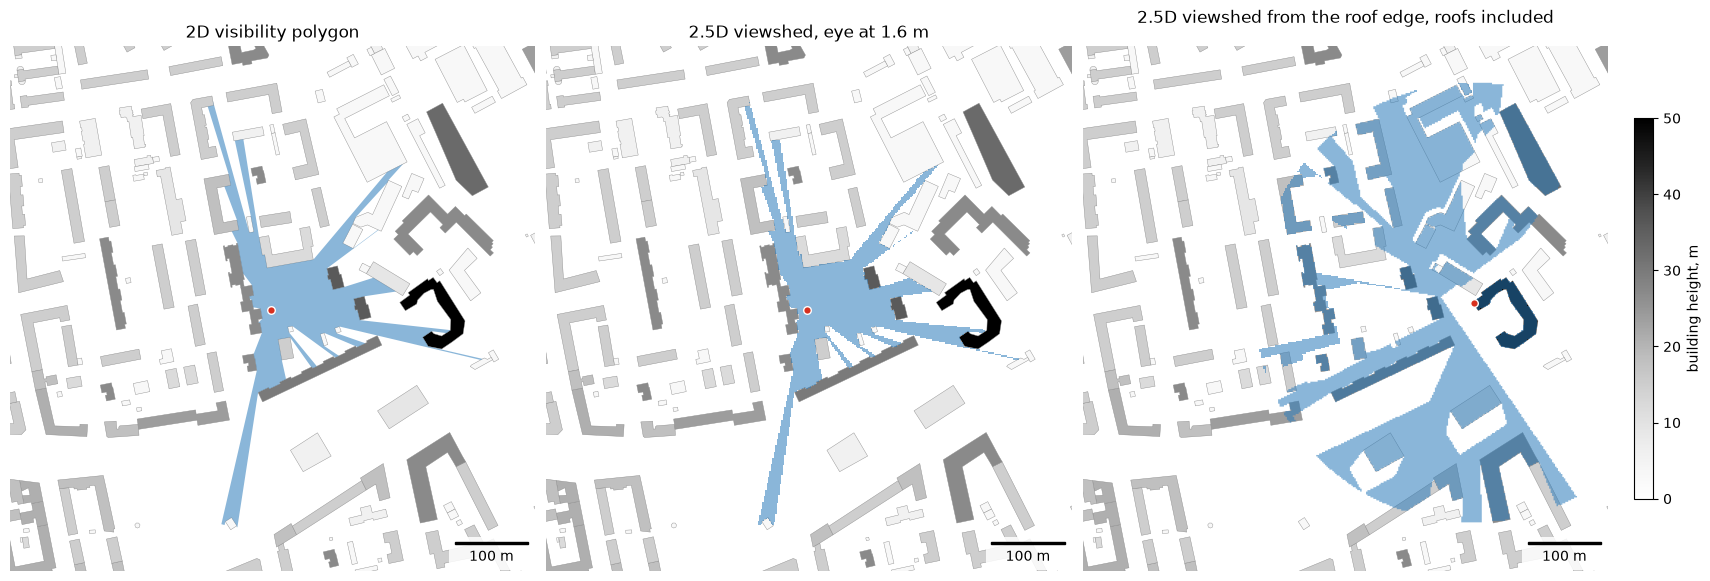

In [6]:
from matplotlib import colors as mcolors

hnorm = mcolors.Normalize(0, 50)
heights = scene["storeys_count"].fillna(1) * 3
fig, axs = plt.subplots(1, 3, figsize=(17, 5.8), constrained_layout=True)
for ax, result, observer, title in [
    (axs[0], v2d, street, "2D visibility polygon"),
    (axs[1], v_street, street, "2.5D viewshed, eye at 1.6 m"),
    (axs[2], v_roof, roof, "2.5D viewshed from the roof edge, roofs included"),
]:
    scene.plot(ax=ax, column=heights, cmap="Greys", norm=hnorm, edgecolor="#8c8c8c", linewidth=0.3)
    result.plot(ax=ax, color="#2b7bba", alpha=0.55, linewidth=0)
    observer.plot(ax=ax, color="#d7301f", markersize=30, edgecolor="white")
    map_extent(ax, box.bounds, outline=False)
    ax.set_title(title)
fig.colorbar(plt.cm.ScalarMappable(norm=hnorm, cmap="Greys"), ax=axs[2], shrink=0.7, label="building height, m")
plt.show()

On flat ground, among buildings taller than the eye, the street viewshed coincides with the 2D polygon up to the
cell size. The roof observer sees over the lower buildings.

## 2. Target height and terrain

`target_height` is the height above the ground of what is looked at: 0 m for the ground surface, 10 m for the upper
part of a facade or a sign. Terrain is given as for insolation (GeoDataFrame, GeoTIFF or array); here a synthetic
Gaussian hill, 20 m high under the street observer, is passed as an array with an affine transform. The buildings
stand on the hill as well. From the rounded summit the ground falls away ever more steeply (a convex slope), so the
lines of sight from an eye 1.6 m above it pass over the lower slopes and the visible ground shrinks to the hilltop:
the terrain hides the ground below, as the walls do.

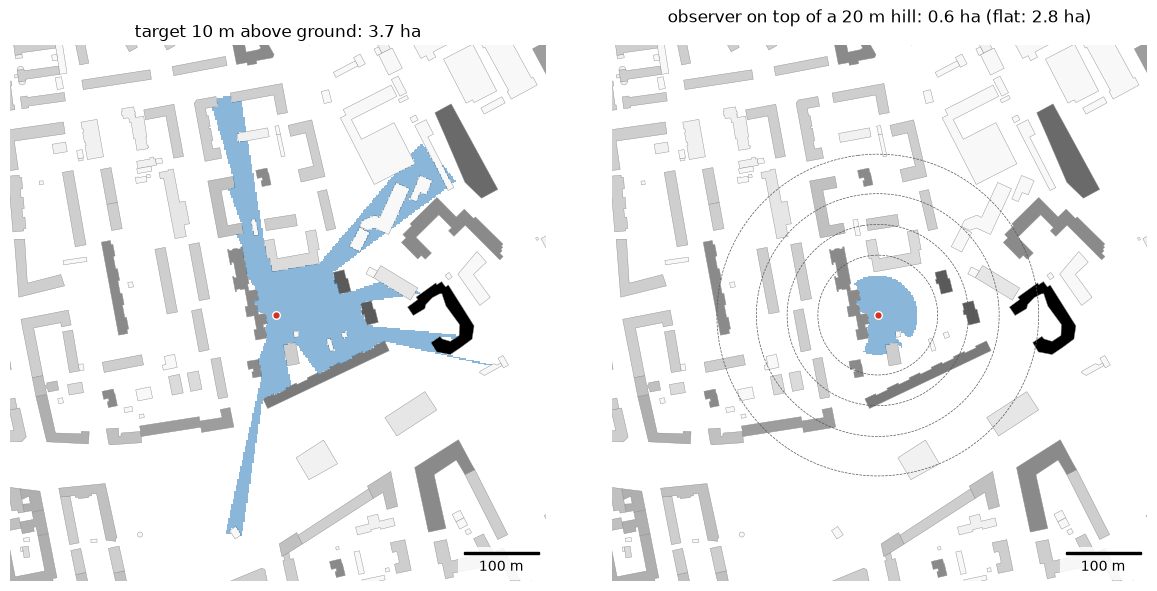

In [7]:
import pandas as pd

v_target = get_viewshed(street, scene, 300, cell_size=2, target_height=10, **HEIGHTS)
# smooth hill as an array: (heights, transform, crs), 2 m cells, 20 m high under the observer
o = street.geometry.iloc[0]
cell = 2.0
x0, y0 = box.bounds[0] - 200, box.bounds[3] + 200  # upper-left corner
cols = rows = int((box.bounds[2] - box.bounds[0] + 400) / cell)
xs = x0 + (np.arange(cols) + 0.5) * cell
ys = y0 - (np.arange(rows) + 0.5) * cell
dist2 = (xs[None, :] - o.x) ** 2 + (ys[:, None] - o.y) ** 2
heights_grid = 20.0 * np.exp(-dist2 / (2 * 120.0**2))
terrain = (heights_grid, (cell, 0.0, x0, 0.0, -cell, y0), scene.crs)
v_hill = get_viewshed(street, scene, 300, cell_size=2, terrain=terrain, **HEIGHTS)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.8), constrained_layout=True)
for ax, result, title in [
    (axs[0], v_target, f"target 10 m above ground: {v_target['visible_area'].iloc[0] / 1e4:.1f} ha"),
    (axs[1], v_hill, f"observer on top of a 20 m hill: {v_hill['visible_area'].iloc[0] / 1e4:.1f} ha (flat: {v_street['visible_area'].iloc[0] / 1e4:.1f} ha)"),
]:
    scene.plot(ax=ax, column=heights, cmap="Greys", norm=hnorm, edgecolor="#8c8c8c", linewidth=0.3)
    result.plot(ax=ax, color="#2b7bba", alpha=0.55, linewidth=0)
    street.plot(ax=ax, color="#d7301f", markersize=30, edgecolor="white")
    map_extent(ax, box.bounds, outline=False)
    ax.set_title(title)
axs[1].contour(xs, ys, heights_grid, levels=[4, 8, 12, 16], colors="#555555", linewidths=0.5, linestyles="--")
plt.show()

## 3. Catchment zones of many observers

Observers are usually placed along streets with `get_observer_points(urban_graph, spacing=15)` on an IduEdu walk
graph. To keep this notebook independent of OpenStreetMap downloads, observers are placed every 15 m on open ground
within 12 m of a building, which approximates sidewalks and yards. They cover the shown area extended by the view
distance (250 m): a cell near the edge of the area is also seen by observers outside it, and without them its
count would come out too low.

Each cell gets the number of observers that see it. Explicit class bounds (`classes=[1, 5, 20, 50]`) put both
results on one scale. The 2.5D catchment uses `target_height=10`: it counts the observers that see a point 10 m above
the ground.

In [8]:
inner = box.buffer(-50, join_style="mitre")  # the area shown below
# observers also around it, up to the view distance; buildings far enough around them
wide_scene = buildings[buildings.intersects(inner.buffer(500))]
observers = open_points(inner.buffer(250, join_style="mitre"), 15, min_dist=2, max_dist=12, obstacles=wide_scene)
bounds = [1, 5, 20, 50]
c2d = get_visibility_catchment(observers, wide_scene, view_distance=250, cell_size=4, classes=bounds)
c25 = get_viewshed_catchment(observers, wide_scene, view_distance=250, cell_size=4, classes=bounds, target_height=10,
                             **HEIGHTS)
print(len(observers), "observers")
pd.concat({"2D": c2d.drop(columns="geometry").assign(area_ha=c2d.area / 1e4),
           "2.5D": c25.drop(columns="geometry").assign(area_ha=c25.area / 1e4)}).round(2)

1805 observers


visibility_class  count_min  count_max  area_ha
2D   0                 1          1          4    21.25
     1                 2          5         19    50.23
     2                 3         20         49    68.31
     3                 4         50         96    16.92
2.5D 0                 1          1          4    19.93
     1                 2          5         19    43.20
     2                 3         20         49    67.59
     3                 4         50        119    33.78

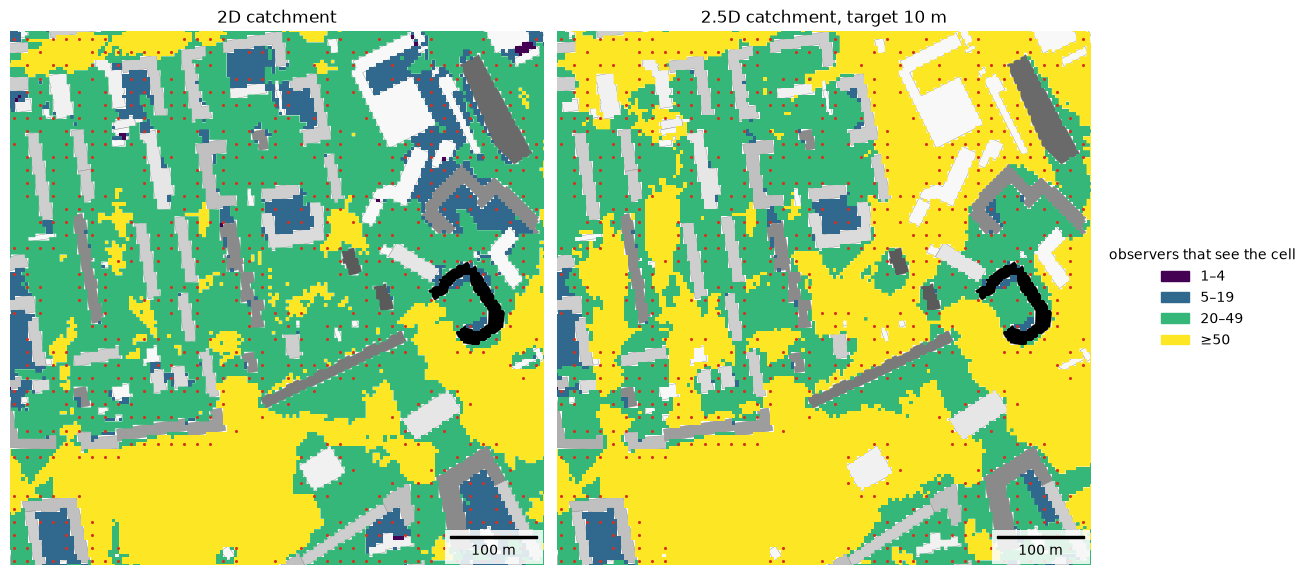

In [9]:
from matplotlib.patches import Patch

cmap = plt.get_cmap("viridis", len(bounds))
labels = ["1–4", "5–19", "20–49", "≥50"]
fig, axs = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, result, title in [(axs[0], c2d, "2D catchment"), (axs[1], c25, "2.5D catchment, target 10 m")]:
    scene.plot(ax=ax, column=heights, cmap="Greys", norm=hnorm, edgecolor="#8c8c8c", linewidth=0.3)
    result.plot(ax=ax, color=[cmap(c - 1) for c in result["visibility_class"]], linewidth=0)
    observers.plot(ax=ax, color="#d7301f", markersize=1.5)
    map_extent(ax, inner.bounds, outline=False)
    ax.set_title(title)
axs[1].legend(handles=[Patch(color=cmap(k), label=lab) for k, lab in enumerate(labels)],
              title="observers that see the cell", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

## 4. Your own area

Buildings with heights and observers: the 2.5D catchment as a raster of observer counts. `output="cells"` returns
the cells seen by at least one observer with their `count`, and `rasterize` puts them back on the calculation grid.
The [visibility notebook](visibility.ipynb) draws the 2D catchment in the same units and on the same colour scale.
`Raster.plot` draws the raster, `Raster.explore` shows it on a web map with a colour bar and `Raster.to_geotiff`
writes a GeoTIFF for GIS (requires `rasterio`).

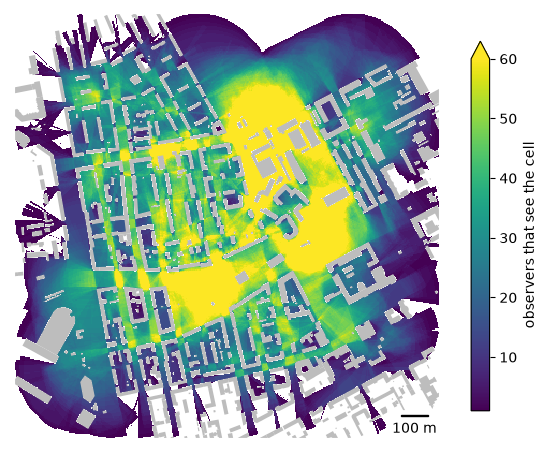

In [10]:
from objectnat import rasterize

my_buildings = wide_scene  # your footprints with heights or storeys (see HEIGHTS)
my_observers = observers    # your observers, also around the area, e.g. get_observer_points(urban_graph, spacing=15)

cells = get_viewshed_catchment(my_observers, my_buildings, view_distance=250, cell_size=4, target_height=10,
                               output="cells", **HEIGHTS)
seen = rasterize(cells, "count")
fig, ax = plt.subplots(figsize=(7, 6))
im = seen.plot(ax=ax, cmap="viridis", vmin=1, vmax=60)
my_buildings.clip(shapely.box(*seen.bounds)).plot(ax=ax, color="#bdbdbd", linewidth=0)
map_extent(ax, seen.bounds, outline=False)
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="observers that see the cell")
plt.show()
# seen.to_geotiff("my_viewshed_count.tif")  # for GIS


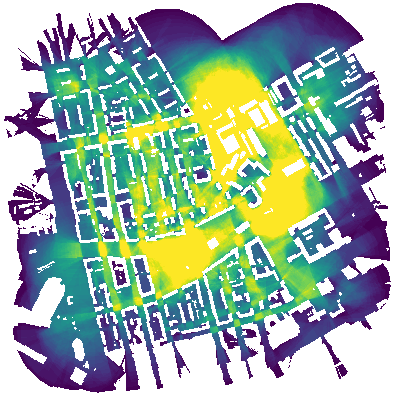

In [11]:
seen.explore(cmap="viridis", vmin=1, vmax=60, name="observers that see the cell")

## Limitations

Roofs are flat and walls vertical; trees and street furniture do not block the view. Results are discrete at
`cell_size`, and computation time per observer grows with `(view_distance / cell_size) ** 2`.